# 01 - Explore the data
**Project:** Malawi Crop Price Seasonality
**Question:** Which crops (beyond maize) have a reliable seasonal price pattern, and when is the best time to sell?

**This notebook:** load both raw files, check their quality, and decide which crops have enough price history to analyse.
No cleaning is saved yet. That happens in `02_clean`.

Sources: WFP Food Prices for Malawi (HDX) and FAOSTAT crop production.

In [14]:
import pandas as pd
import plotly.express as px
from pathlib import Path

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)

# This notebook lives in notebooks/, the data lives in raw_data/
ROOT = Path.cwd()
while not (ROOT / "raw_data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

RAW = ROOT / "raw_data"
WFP_FILE = RAW / "wfp_food_prices_mwi.csv"
FAO_FILE = next(RAW.glob("FAOSTAT*.csv"))   # picks up the FAOSTAT file whatever its date
print(WFP_FILE.exists(), FAO_FILE.name)

True FAOSTAT_data_en_10-12-2026.csv


## 1. WFP price data: first look

In [16]:
wfp = pd.read_csv(WFP_FILE, parse_dates=["date"])
print(wfp.shape)
wfp.head()

(88769, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,1990-10-15,NaN,NaN,National Average,1835,NaN,NaN,non-food,Fuel (diesel),284,L,actual,Retail,MWK,1.90,0.0130
1,1990-10-15,NaN,NaN,National Average,1835,NaN,NaN,non-food,"Fuel (kerosene, paraffin)",350,L,actual,Retail,MWK,1.22,0.0087
2,1991-08-15,NaN,NaN,National Average,1835,NaN,NaN,non-food,Fuel (diesel),284,L,actual,Retail,MWK,2.00,0.0140
3,1991-08-15,NaN,NaN,National Average,1835,NaN,NaN,non-food,"Fuel (kerosene, paraffin)",350,L,actual,Retail,MWK,1.22,0.0087
4,1992-06-15,NaN,NaN,National Average,1835,NaN,NaN,non-food,Fuel (diesel),284,L,actual,Retail,MWK,2.58,0.0180


In [17]:
wfp.dtypes

date            datetime64[us]
admin1                     str
admin2                     str
market                     str
market_id                int64
latitude               float64
longitude              float64
category                   str
commodity                  str
commodity_id             int64
unit                       str
priceflag                  str
pricetype                  str
currency                   str
price                  float64
usdprice               float64
dtype: object

## 2. Quality checks

In [18]:
print("Date range:", wfp["date"].min().date(), "to", wfp["date"].max().date())
print("Markets:", wfp["market"].nunique(), "| Commodities:", wfp["commodity"].nunique())
print("Duplicate rows (date, market, commodity, unit):",
      wfp.duplicated(["date", "market_id", "commodity", "unit"]).sum())
print("Zero or negative prices:", (wfp["price"] <= 0).sum())
print()
print("Missing values per column:")
print(wfp.isna().sum()[wfp.isna().sum() > 0])

Date range: 1990-10-15 to 2026-10-15
Markets: 130 | Commodities: 63
Duplicate rows (date, market, commodity, unit): 0
Zero or negative prices: 0

Missing values per column:
admin1       642
admin2       642
latitude     642
longitude    642
dtype: int64


In [19]:
# How were prices produced? 'actual' = observed, 'aggregate' = compiled/estimated
wfp["priceflag"].value_counts(normalize=True).round(3)

priceflag
aggregate           0.763
actual              0.226
actual,aggregate    0.011
Name: proportion, dtype: float64

In [20]:
# Rows per month in the most recent months. The latest month is usually incomplete.
wfp.groupby("date").size().tail(6)

date
2026-05-15    1684
2026-06-15    1936
2026-07-15    1928
2026-08-15    1931
2026-09-15    2009
2026-10-15      94
dtype: int64

**Note:** the final month has far fewer rows than the months before it, so it is incomplete.
We will drop any incomplete trailing month in `02_clean`.

## 3. Which commodities exist, and how much history does each have?

In [21]:
coverage = (
    wfp.groupby(["category", "commodity", "unit"])
       .agg(rows=("price", "size"),
            first=("date", "min"),
            last=("date", "max"),
            years=("date", lambda s: s.dt.year.nunique()),
            markets=("market", "nunique"))
       .reset_index()
       .sort_values("rows", ascending=False)
)
coverage

,category,commodity,unit,rows,first,last,years,markets
2,cereals and tubers,Maize,KG,14476,2003-01-15,2026-10-15,22,129
46,pulses and nuts,Beans,KG,6746,2012-06-15,2026-10-15,15,127
8,cereals and tubers,Rice,KG,5095,2007-01-15,2026-09-15,18,127
49,pulses and nuts,Groundnuts (shelled),KG,3906,2012-06-15,2026-09-15,11,125
48,pulses and nuts,Cowpeas,KG,3710,2015-05-15,2026-10-15,9,113
1,cereals and tubers,Cassava,KG,2816,2007-02-15,2026-09-15,18,126
50,pulses and nuts,Pigeon peas,KG,2802,2015-05-15,2026-10-15,8,105
3,cereals and tubers,Maize (new harvest),KG,2730,2020-11-15,2025-08-15,5,100
20,miscellaneous food,Sugar,KG,2134,2020-11-15,2026-10-15,4,99
45,oil and fats,Oil (vegetable),L,2131,2020-11-15,2026-10-15,4,99


Seasonality needs many years. A rule of thumb for this project: **at least 5 distinct years** and **at least 20 markets**.

In [22]:
MIN_YEARS, MIN_MARKETS = 5, 20
food = coverage[coverage["category"] != "non-food"]
usable = food[(food["years"] >= MIN_YEARS) & (food["markets"] >= MIN_MARKETS)]
too_short = food[~food.index.isin(usable.index)]
print("Usable for seasonality:")
display(usable[["commodity", "unit", "years", "markets", "first", "last"]])
print("Too short for now:")
display(too_short[["commodity", "unit", "years", "markets", "first", "last"]].head(15))

Usable for seasonality:


,commodity,unit,years,markets,first,last
2,Maize,KG,22,129,2003-01-15,2026-10-15
46,Beans,KG,15,127,2012-06-15,2026-10-15
8,Rice,KG,18,127,2007-01-15,2026-09-15
49,Groundnuts (shelled),KG,11,125,2012-06-15,2026-09-15
48,Cowpeas,KG,9,113,2015-05-15,2026-10-15
1,Cassava,KG,18,126,2007-02-15,2026-09-15
50,Pigeon peas,KG,8,105,2015-05-15,2026-10-15
3,Maize (new harvest),KG,5,100,2020-11-15,2025-08-15


Too short for now:


,commodity,unit,years,markets,first,last
20,Sugar,KG,4,99,2020-11-15,2026-10-15
45,Oil (vegetable),L,4,99,2020-11-15,2026-10-15
13,Eggs,Unit,4,99,2020-11-15,2026-09-15
12,Sweet potatoes,KG,4,99,2020-11-15,2026-09-15
51,Soybeans,KG,2,97,2025-03-15,2026-09-15
62,Tomatoes,KG,2,97,2025-09-15,2026-09-15
56,Exotic vegetables,KG,2,97,2025-09-15,2026-09-15
17,"Fish (small, dry)",KG,2,97,2025-09-15,2026-09-15
57,Local vegetables,KG,2,97,2025-09-15,2026-09-15
59,Onions,Unit,3,99,2020-11-15,2025-08-15


## 4. Coverage by year: where are the gaps?

In [23]:
core = usable["commodity"].tolist()
by_year = (wfp[wfp["commodity"].isin(core)]
           .pivot_table(index=wfp["date"].dt.year, columns="commodity",
                        values="price", aggfunc="size")
           .fillna(0).astype(int))
by_year

commodity,Beans,Cassava,Cowpeas,Groundnuts (shelled),Maize,Maize (new harvest),Pigeon peas,Rice
date,,,,,,,,
2003,0,0,0,0,211,0,0,0
2004,0,0,0,0,440,0,0,0
2005,0,0,0,0,604,0,0,0
2006,0,0,0,0,722,0,0,0
2007,0,11,0,0,789,0,0,24
2008,0,12,0,0,770,0,0,24
2009,0,12,0,0,480,0,0,24
2010,0,12,0,0,449,0,0,21
2011,0,8,0,0,606,0,0,12


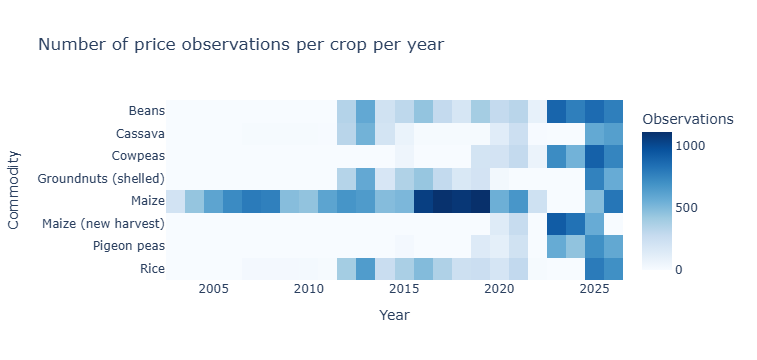

In [24]:
fig = px.imshow(by_year.T, aspect="auto", color_continuous_scale="Blues",
                labels=dict(x="Year", y="Commodity", color="Observations"),
                title="Number of price observations per crop per year")
fig.show()

Look for years where a crop drops to zero or near zero. Those gaps matter when we compute seasonal patterns.

## 5. Why we cannot use raw prices: inflation

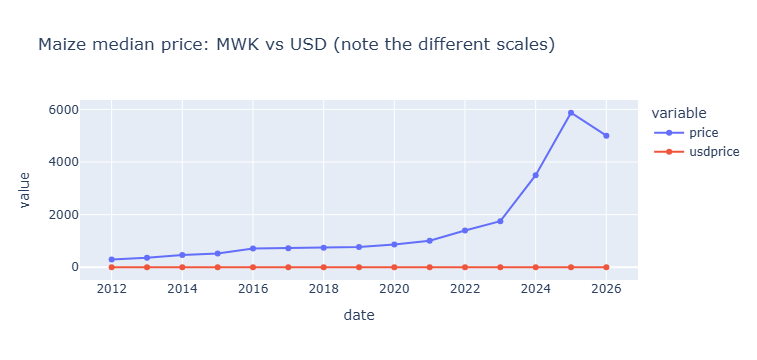

In [25]:
maize = wfp[wfp["commodity"] == "Beans"]
yearly = maize.groupby(maize["date"].dt.year)[["price", "usdprice"]].median().reset_index()
fig = px.line(yearly, x="date", y=["price", "usdprice"], markers=True,
              title="Maize median price: MWK vs USD (note the different scales)")
fig.show()

Maize in MWK climbs from tens to hundreds to over a thousand. Any seasonal swing is buried under that trend.
In the next notebook we divide each price by that year's average (a **seasonal index**) so years are comparable.

## 6. FAOSTAT production data (crop context)

In [26]:
fao = pd.read_csv(FAO_FILE)
print(fao.shape, "| Years:", sorted(fao["Year"].unique()))
prod = (fao[fao["Element"] == "Production"]
        .pivot_table(index="Item", columns="Year", values="Value")
        .sort_values(2024, ascending=False))
prod.head(20)

(343, 15) | Years: [np.int64(2023), np.int64(2024)]


Year,2023,2024
Item,,
Sweet potatoes,7609426.000,7980472.780
"Cassava, fresh",6195735.000,6278880.490
Maize (corn),3509837.000,3000000.000
Sugar cane,2648500.000,2965639.290
Potatoes,1516396.000,1457542.380
"Mangoes, guavas and mangosteens",1357653.000,1384976.440
Bananas,1077474.000,1131259.420
Tomatoes,694260.000,680945.610
"Pigeon peas, dry",456033.000,473662.070


In [27]:
fao["Flag Description"].value_counts()

Flag Description
Estimated value                        202
Value imputed by a receiving agency     94
Official value                          31
Value from external organization        16
Name: count, dtype: int64

## 7. Findings

This first pass told me what the data can and can't support before I build anything on it.

- **Usable crops (5+ years, 20+ markets):** Seven crops clear the bar: maize, beans, rice, groundnuts, cowpeas, pigeon peas and cassava. Each has between 8 and 22 years of prices across roughly 100 to 130 markets. Maize is by far the best covered, going back to 2003. (Adjust this count to match the table in your own output.)
- **Crops too short for seasonality:** Soybeans, tomatoes, potatoes and onions have only 1 to 2 years of prices, which is not enough to say anything about seasonal patterns. Sweet potatoes, sorghum and millet sit in between: they have a few years of data, but with long breaks. I will treat them as indicative at best, and soybeans, despite being a notable crop in the FAOSTAT data, as "insufficient data".
- **Biggest data gaps:** 2022 is nearly empty for most crops. Maize and rice have no prices at all for 2023 to 2024, and several crops stop in 2021 and only resume in 2025. Earlier years also have far fewer markets reporting, so older averages rest on a handful of places. These gaps mean recent-year evidence is thin, and I will be careful not to overstate it.
- **Incomplete months to drop:** The final month, October 2026, has only 94 rows against about 2,000 the month before. It is a partial month, so it is dropped.
- **Naming mismatches to fix between WFP and FAOSTAT:** The two sources name the same crops differently, for example "Beans" and "Beans, dry", "Cassava" and "Cassava, fresh", and "Groundnuts (shelled)" and "Groundnuts, excluding shelled". Millet does not appear in my FAOSTAT extract at all. WFP also splits maize into several labels (new harvest, white, seed), which I exclude to avoid counting the same crop twice. All of this is handled with a mapping table in `02_clean`.
- **Why raw prices can't be used:** Maize rose from around 13 MWK/kg in 2003 to over 900 in 2026. Inflation swamps any seasonal swing, so the analysis compares each month's price with its local trend instead of using raw prices.

**Takeaway:** There is enough history to analyse seasonality for a core group of crops, but not for every crop, and the recent years are the weakest part of the data. The conclusions will lean mostly on the long-run pattern, and I will state clearly where the evidence is strong and where it is only a hint.

**Next:** `02_clean.ipynb` filters to the usable food crops, drops the incomplete month, standardises names, builds the WFP-to-FAOSTAT mapping and saves the result to `clean_data/`. After that, `03_seasonality.ipynb` builds the monthly seasonal index.